#El Perceptrón con Python y scikit-learn

**Caso de estudio:** clasificar flores del dataset *Iris* en dos especies (**setosa** vs **versicolor**) a partir del largo y el ancho de su pétalo.

**Objetivo:** mostrar, paso a paso, cómo funciona y cómo se implementa un **Perceptrón** (el modelo más simple de red neuronal), siguiendo todas las etapas de un *pipeline* de Machine Learning. Además, lo programaremos **desde cero con NumPy** para ver su regla de aprendizaje en acción.


## 1. Fundamentos teóricos del Perceptrón

### 1.1 Origen
El Perceptrón fue propuesto por **Frank Rosenblatt en 1958**, inspirado en el funcionamiento de una **neurona biológica**:

| Neurona biológica | Perceptrón |
|---|---|
| Dendritas reciben señales | Entradas $x_1, x_2,\dots,x_d$ |
| Cada conexión tiene distinta "fuerza" | Pesos $w_1, w_2,\dots,w_d$ |
| El cuerpo celular suma las señales | Suma ponderada $z=\sum w_jx_j+b$ |
| La neurona "dispara" si se supera un umbral | Función de activación escalón |
| Axón transmite la salida | Salida $\hat y\in\{0,1\}$ |

### 1.2 ¿Qué problema resuelve?
Es un **clasificador binario supervisado**: dado un conjunto de ejemplos con su etiqueta correcta (clase 0 o clase 1), aprende una regla para asignar la clase a ejemplos nuevos.

### 1.3 La idea geométrica
El Perceptrón es un **clasificador lineal**: dibuja una **línea recta** (en 2 dimensiones), un **plano** (en 3) o un **hiperplano** (en más) que separa las dos clases.

- Los puntos de un lado de la línea se clasifican como clase 1.
- Los del otro lado, como clase 0.

### 1.4 Aprendizaje: aprender de los errores
El Perceptrón aprende **corrigiendo sus errores**:

1. Toma un ejemplo y predice su clase.
2. Si acierta, no cambia nada.
3. Si se equivoca, **mueve ligeramente la línea** para que ese ejemplo quede más cerca del lado correcto.
4. Repite con todos los ejemplos, varias veces (cada pasada completa se llama **época**), hasta que ya no cometa errores o se alcance un máximo de épocas.

### 1.5 Teorema de convergencia (Rosenblatt / Novikoff)
Si las dos clases son **linealmente separables** (existe al menos una línea recta que las separa perfectamente), el algoritmo **garantiza** encontrar una línea que las separe en un **número finito** de correcciones.

### 1.6 Limitaciones
- Solo resuelve problemas **linealmente separables**. El ejemplo clásico donde falla es la función **XOR** (Minsky y Papert, 1969), que veremos en la sección 3.11.
- Su salida es una clase dura (0 o 1): **no da probabilidades**.
- Si los datos no son separables, el algoritmo **nunca converge** y sigue oscilando.

Estas limitaciones motivaron las **redes multicapa** (*Multilayer Perceptron*, MLP), que apilan varias neuronas y funciones de activación no lineales.

## 2. Modelo matemático y analítico

### 2.1 Notación
- Un ejemplo con $d$ características: $\mathbf{x}=(x_1,\dots,x_d)^\top$ (aquí $d=2$: largo y ancho del pétalo).
- Vector de pesos: $\mathbf{w}=(w_1,\dots,w_d)^\top$.
- Sesgo (*bias*): $b$. Desplaza la frontera de decisión.
- Etiqueta real: $y\in\{0,1\}$. Predicción: $\hat y\in\{0,1\}$.

### 2.2 Paso 1: suma ponderada
$$z=\mathbf{w}^\top\mathbf{x}+b=w_1x_1+w_2x_2+\dots+w_dx_d+b$$

### 2.3 Paso 2: función de activación escalón
$$
\hat y=\phi(z)=\begin{cases}1 & \text{si } z\ge 0\\[2pt] 0 & \text{si } z<0\end{cases}
$$

### 2.4 Interpretación geométrica
La frontera de decisión es el conjunto de puntos donde $z=0$:

$$\mathbf{w}^\top\mathbf{x}+b=0$$

- En 2D es una **recta**: $w_1x_1+w_2x_2+b=0$.
- El vector $\mathbf{w}$ es **perpendicular** a esa recta y apunta hacia el lado de la clase 1.
- La distancia de un punto a la recta es $\dfrac{|z|}{\|\mathbf{w}\|}$: cuanto mayor es $|z|$, más "seguro" está el punto de su clase.
- El sesgo $b$ mueve la recta sin rotarla.

### 2.5 Regla de aprendizaje
Para cada ejemplo $(\mathbf{x},y)$ y con **tasa de aprendizaje** $\eta>0$:

$$
\begin{aligned}
\mathbf{w}&\leftarrow\mathbf{w}+\eta\,(y-\hat y)\,\mathbf{x}\\
b&\leftarrow b+\eta\,(y-\hat y)
\end{aligned}
$$

El término $(y-\hat y)$ solo puede valer:

| $y$ | $\hat y$ | $y-\hat y$ | Efecto |
|---|---|---|---|
| 1 | 1 | 0 | Acertó: no se cambia nada |
| 0 | 0 | 0 | Acertó: no se cambia nada |
| 1 | 0 | **+1** | Se **suma** $\eta\mathbf{x}$ a $\mathbf{w}$: $z$ aumenta, se acerca a clasificar como 1 |
| 0 | 1 | **−1** | Se **resta** $\eta\mathbf{x}$ a $\mathbf{w}$: $z$ disminuye, se acerca a clasificar como 0 |

### 2.6 Ejemplo numérico de una actualización
Sea $\mathbf{w}=(0.5,\,-1)$, $b=0$, $\eta=0.1$ y un ejemplo $\mathbf{x}=(1,\,2)$ con $y=1$.

1. $z=0.5\cdot1+(-1)\cdot2+0=-1.5$ → como $z<0$, $\hat y=0$. **Error:** $y-\hat y=1$.
2. Actualización: $\mathbf{w}=(0.5+0.1\cdot1,\;-1+0.1\cdot2)=(0.6,\,-0.8)$ y $b=0+0.1=0.1$.
3. Nuevo $z=0.6\cdot1+(-0.8)\cdot2+0.1=-0.9$.

El valor pasó de $-1.5$ a $-0.9$: **se acercó a cero** (a clasificar bien). Con más correcciones llegaría a ser positivo.

### 2.7 Fundamento analítico: de dónde sale la regla
La regla es un **descenso de gradiente estocástico** sobre la **pérdida del Perceptrón**. Con etiquetas codificadas como $t\in\{-1,+1\}$:

$$L(\mathbf{w},b)=\sum_{i\in\mathcal{M}}-\,t_i\,(\mathbf{w}^\top\mathbf{x}_i+b)$$

donde $\mathcal{M}$ es el conjunto de ejemplos mal clasificados. Cada término es positivo para un error (porque $t_i$ y $z_i$ tienen signos opuestos) y cero para los aciertos. Derivando respecto a $\mathbf{w}$ y $b$ para un solo ejemplo mal clasificado:

$$\frac{\partial L_i}{\partial\mathbf{w}}=-t_i\mathbf{x}_i,\qquad\frac{\partial L_i}{\partial b}=-t_i$$

y dando un paso en dirección opuesta al gradiente: $\mathbf{w}\leftarrow\mathbf{w}+\eta\,t_i\mathbf{x}_i$, $b\leftarrow b+\eta\,t_i$. Es exactamente la regla de la sección 2.5.

### 2.8 Garantía de convergencia
Si existe un hiperplano que separa las clases con margen $\gamma>0$ y todos los ejemplos cumplen $\|\mathbf{x}_i\|\le R$, el número total de correcciones está acotado por

$$\text{número de errores}\;\le\;\left(\frac{R}{\gamma}\right)^2$$

Mientras más separadas estén las clases (mayor $\gamma$), más rápido converge.

### 2.9 Métricas de evaluación
Con los conteos: **VP** (verdaderos positivos), **VN** (verdaderos negativos), **FP** (falsos positivos), **FN** (falsos negativos):

| Métrica | Fórmula | Interpretación |
|---|---|---|
| Exactitud (*accuracy*) | $\dfrac{VP+VN}{VP+VN+FP+FN}$ | Proporción de aciertos totales |
| Precisión | $\dfrac{VP}{VP+FP}$ | De los que predije clase 1, ¿cuántos lo eran? |
| Exhaustividad (*recall*) | $\dfrac{VP}{VP+FN}$ | De los que eran clase 1, ¿cuántos detecté? |
| $F_1$ | $2\cdot\dfrac{\text{precisión}\cdot\text{recall}}{\text{precisión}+\text{recall}}$ | Media armónica de precisión y recall |

La **matriz de confusión** organiza VP, VN, FP y FN en una tabla de 2×2.

### 2.10 Por qué conviene estandarizar las características
Si una variable tiene una escala mucho mayor que otra, domina la suma ponderada y las correcciones se vuelven desiguales. Estandarizar ($z=\frac{x-\bar x}{s}$) pone todas las variables en escalas comparables y acelera la convergencia.

## 3. Pipeline de Machine Learning

Etapas que seguiremos:

`Recolección de datos → Descripción/EDA → Scatter plot → Preparación → Entrenamiento → Evaluación → Predicción`

### Paso 0. Importar las librerías

In [3]:
# Importamos NumPy: arreglos numéricos y álgebra lineal
import numpy as np
# Importamos pandas: manejo de datos tabulares (DataFrame)
import pandas as pd
# Importamos matplotlib: gráficos
import matplotlib.pyplot as plt
# Importamos warnings para controlar avisos que son esperables en la sección del problema XOR
import warnings
# Importamos load_iris: carga el dataset Iris que viene incluido en scikit-learn
from sklearn.datasets import load_iris as iris
# Importamos train_test_split (partición) y cross_val_score/StratifiedKFold (validación cruzada)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
# Importamos StandardScaler: estandariza las características (media 0, desviación 1)
from sklearn.preprocessing import StandardScaler
# Importamos Perceptron: la implementación del Perceptrón en scikit-learn
from sklearn.linear_model import Perceptron
# Importamos Pipeline: encadena escalado -> Perceptrón en un solo objeto
from sklearn.pipeline import Pipeline
# Importamos las métricas de clasificación
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

# Fijamos una semilla para que los resultados sean reproducibles
SEED = 42

### 3.1 Recolección de datos

Usaremos el clásico dataset **Iris**. Contiene 150 flores de 3 especies con 4 mediciones cada una. Para tener un problema **binario** y **linealmente separable**, nos quedaremos solo con:

- **Clases:** *setosa* (etiqueta 0) y *versicolor* (etiqueta 1).
- **Características:** largo del pétalo y ancho del pétalo (en cm).

Esto nos permite además visualizar todo en un plano de 2 dimensiones.

In [4]:
# Cargamos el dataset Iris como DataFrame de pandas (as_frame=True incluye los nombres de columnas)
iris = load_iris(as_frame=True)
# Extraemos la tabla completa (4 características + columna 'target' con la clase 0, 1 o 2)
data = iris.frame
# Nos quedamos solo con las clases 0 (setosa) y 1 (versicolor) para un problema binario
data = data[data["target"].isin([0, 1])]
# Seleccionamos únicamente largo y ancho del pétalo, más la etiqueta
df = data[["petal length (cm)", "petal width (cm)", "target"]].copy()
# Renombramos las columnas con nombres cortos y sin espacios
df.columns = ["largo_petalo", "ancho_petalo", "clase"]
# Reiniciamos el índice para que vaya de 0 a 99
df = df.reset_index(drop=True)
# Mostramos las primeras 5 filas para verificar la carga
df.head()

,largo_petalo,ancho_petalo,clase
0,1.4,0.2,0
1,1.4,0.2,0
2,1.3,0.2,0
3,1.5,0.2,0
4,1.4,0.2,0


### 3.2 Descripción y análisis del dataset (EDA)

Antes de modelar hay que entender los datos: tamaño, tipos, valores faltantes, estadísticos, balance de clases y relación entre variables.

In [6]:
# Imprimimos el número de filas y columnas del dataset
print("Dimensiones (filas, columnas):", df.shape)
# Contamos los valores faltantes por columna (esperamos 0)
print("\nValores nulos por columna:\n", df.isnull().sum())
# Contamos cuántos ejemplos hay de cada clase (para ver si las clases están balanceadas)
print("\nEjemplos por clase (0 = setosa, 1 = versicolor):\n", df["clase"].value_counts())

Dimensiones (filas, columnas): (100, 3)

Valores nulos por columna:
 largo_petalo    0
ancho_petalo    0
clase           0
dtype: int64

Ejemplos por clase (0 = setosa, 1 = versicolor):
 clase
0    50
1    50
Name: count, dtype: int64


In [ ]:
# Calculamos estadísticos descriptivos (media, desviación, mínimo, cuartiles, máximo) de las características
df[["largo_petalo", "ancho_petalo"]].describe().round(2)

,largo_petalo,ancho_petalo
count,100.00,100.00
mean,2.86,0.79
std,1.45,0.57
min,1.00,0.10
25%,1.50,0.20
50%,2.45,0.80
75%,4.32,1.30
max,5.10,1.80


In [ ]:
# Calculamos la media de cada característica por clase: si difieren mucho, la clase es fácil de separar
df.groupby("clase")[["largo_petalo", "ancho_petalo"]].mean().round(2)

,largo_petalo,ancho_petalo
clase,,
0,1.46,0.25
1,4.26,1.33


In [ ]:
# Calculamos la correlación de Pearson entre todas las columnas (incluida la clase)
df.corr().round(3)

,largo_petalo,ancho_petalo,clase
largo_petalo,1.000,0.979,0.97
ancho_petalo,0.979,1.000,0.96
clase,0.970,0.960,1.00


**Lectura del EDA.**

- El dataset es **balanceado** (50 ejemplos por clase), así que la exactitud (*accuracy*) es una métrica razonable.
- No hay valores faltantes.
- Las medias de largo y ancho del pétalo son **muy distintas** entre las dos especies, lo que anticipa que las clases serán fáciles de separar.
- La fuerte correlación de ambas variables con la clase confirma que son buenas características para clasificar.

### 3.3 Scatter plot

El diagrama de dispersión muestra si las clases pueden separarse con una **línea recta**, que es justo la condición que necesita el Perceptrón.

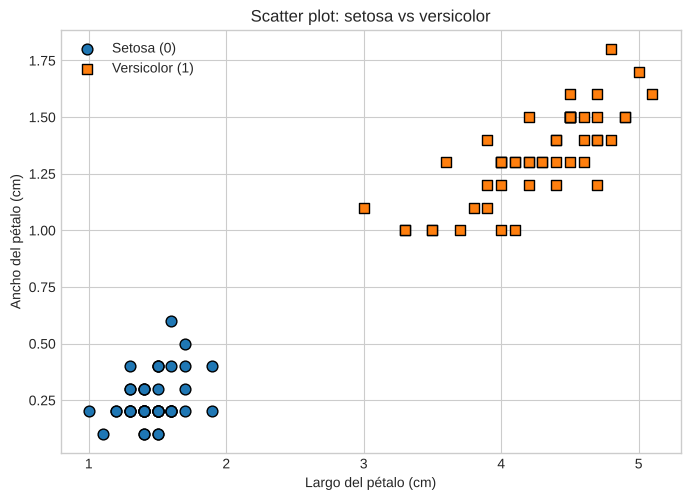

In [ ]:
# Creamos una figura de 8x5.5 pulgadas
plt.figure(figsize=(8, 5.5))
# Dibujamos los puntos de setosa (clase 0)
plt.scatter(df.loc[df["clase"] == 0, "largo_petalo"], df.loc[df["clase"] == 0, "ancho_petalo"],
            color="tab:blue", edgecolor="k", s=60, label="Setosa (0)")
# Dibujamos los puntos de versicolor (clase 1)
plt.scatter(df.loc[df["clase"] == 1, "largo_petalo"], df.loc[df["clase"] == 1, "ancho_petalo"],
            color="tab:orange", edgecolor="k", s=60, marker="s", label="Versicolor (1)")
# Etiqueta del eje X
plt.xlabel("Largo del pétalo (cm)")
# Etiqueta del eje Y
plt.ylabel("Ancho del pétalo (cm)")
# Título del gráfico
plt.title("Scatter plot: setosa vs versicolor")
# Mostramos la leyenda
plt.legend()
# Mostramos el gráfico
plt.show()

**Observación:** los dos grupos forman nubes **claramente separadas**, y se podría trazar una recta entre ellas sin cometer errores. Es decir, el problema es **linealmente separable**, así que el teorema de convergencia (sección 1.5) garantiza que el Perceptrón encontrará una solución.

### 3.4 Preparación de los datos

1. Separar las características $X$ (matriz de $m\times2$) de la etiqueta $y$ (vector).
2. Dividir en **entrenamiento (75 %)** y **prueba (25 %)**. Usamos `stratify=y` para que ambas particiones conserven la proporción 50/50 de clases.

> El escalado lo incluiremos **dentro del Pipeline**, para que la media y la desviación se calculen **solo con los datos de entrenamiento** y se evite *data leakage* (fuga de información del conjunto de prueba).

In [7]:
# X debe ser una matriz 2D (m filas x 2 columnas) con las características
X = df[["largo_petalo", "ancho_petalo"]].values
# y es un vector 1D con la clase de cada flor (0 o 1)
y = df["clase"].values

# Dividimos en entrenamiento (75 %) y prueba (25 %), manteniendo la proporción de clases (stratify)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

### 3.5 Entrenamiento del modelo

Construimos un *pipeline* con dos pasos: estandarizar y entrenar el Perceptrón. Hiperparámetros principales de `Perceptron`:

- `eta0`: tasa de aprendizaje $\eta$.
- `max_iter`: número máximo de épocas.
- `tol`: criterio de paro; si la mejora es menor que `tol` durante varias épocas seguidas, se detiene.
- `random_state`: semilla para el orden aleatorio de los ejemplos.

In [ ]:
# Construimos el pipeline final
model = Pipeline([
    # Paso 1: estandarizamos las características (parámetros aprendidos solo del conjunto de entrenamiento)
    ("scaler", StandardScaler()),
    # Paso 2: Perceptrón con tasa de aprendizaje 0.1, hasta 1000 épocas y semilla fija
    ("perceptron", Perceptron(eta0=0.1, max_iter=1000, tol=1e-3, random_state=SEED)),
])

# Entrenamos (ajustamos) el modelo con los datos de entrenamiento
model.fit(X_train, y_train)
# Recuperamos el Perceptrón entrenado desde el pipeline
perc = model.named_steps["perceptron"]
# Mostramos en cuántas épocas convergió el algoritmo
print(f"Épocas necesarias para converger: {perc.n_iter_}")
# Mostramos la exactitud sobre los datos de entrenamiento
print(f"Exactitud en entrenamiento: {model.score(X_train, y_train):.4f}")

Épocas necesarias para converger: 6
Exactitud en entrenamiento: 1.0000


### 3.6 Parámetros aprendidos (pesos y sesgo)

El modelo aprendió un vector de pesos $\mathbf{w}$ y un sesgo $b$. **Atención:** están expresados sobre las características **estandarizadas**.

In [ ]:
# Recuperamos el estandarizador entrenado
scaler = model.named_steps["scaler"]
# Extraemos los pesos w (coef_ tiene forma 1 x 2, por eso tomamos la fila 0)
w = perc.coef_[0]
# Extraemos el sesgo b (intercept_ es un arreglo de un elemento)
b = perc.intercept_[0]
# Mostramos la media y la desviación usadas para estandarizar cada característica
print("Media de las características (train):", scaler.mean_.round(3), "| Desviación:", scaler.scale_.round(3))
# Mostramos los pesos aprendidos
print(f"Pesos: w1 (largo) = {w[0]:.4f}, w2 (ancho) = {w[1]:.4f}")
# Mostramos el sesgo aprendido
print(f"Sesgo: b = {b:.4f}")
# Escribimos la regla de decisión resultante
print(f"\nRegla: z = {w[0]:.3f}·z_largo + {w[1]:.3f}·z_ancho + {b:.3f}  ->  clase 1 si z >= 0, clase 0 si z < 0")

Media de las características (train): [2.889 0.787] | Desviación: [1.43  0.552]
Pesos: w1 (largo) = 0.0987, w2 (ancho) = 0.0930
Sesgo: b = 0.1000

Regla: z = 0.099·z_largo + 0.093·z_ancho + 0.100  ->  clase 1 si z >= 0, clase 0 si z < 0


### 3.7 Evaluación de la técnica (métricas)

Evaluamos con el conjunto de **prueba**, que el modelo nunca vio durante el entrenamiento.

In [ ]:
# Obtenemos las predicciones del modelo sobre el conjunto de prueba
y_pred = model.predict(X_test)

# Calculamos la exactitud: proporción de aciertos
acc = accuracy_score(y_test, y_pred)
# Calculamos la precisión de la clase 1 (versicolor)
prec = precision_score(y_test, y_pred)
# Calculamos el recall (exhaustividad) de la clase 1
rec = recall_score(y_test, y_pred)
# Calculamos el F1 (media armónica de precisión y recall)
f1 = f1_score(y_test, y_pred)

# Armamos una tabla con las métricas
pd.DataFrame({"Métrica": ["Exactitud", "Precisión", "Recall", "F1"], "Valor": [acc, prec, rec, f1]}).round(4)

,Métrica,Valor
0,Exactitud,1.0
1,Precisión,1.0
2,Recall,1.0
3,F1,1.0


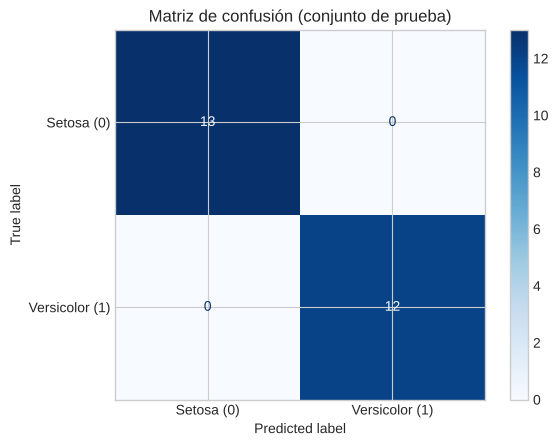

In [ ]:
# Calculamos la matriz de confusión: filas = clase real, columnas = clase predicha
cm = confusion_matrix(y_test, y_pred)
# Creamos el objeto de visualización con los nombres de las clases
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Setosa (0)", "Versicolor (1)"])
# Dibujamos la matriz con un mapa de color azul
disp.plot(cmap="Blues")
# Título del gráfico
plt.title("Matriz de confusión (conjunto de prueba)")
# Mostramos el gráfico
plt.show()

In [ ]:
# Imprimimos el reporte completo de clasificación (precisión, recall y F1 por clase)
print(classification_report(y_test, y_pred, target_names=["Setosa", "Versicolor"]))

              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        13
  Versicolor       1.00      1.00      1.00        12

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25



In [ ]:
# Definimos una validación cruzada estratificada de 5 particiones
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
# Calculamos la exactitud en cada partición usando TODO el dataset
cv_acc = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
# Mostramos la exactitud de cada partición
print("Exactitud por partición:", np.round(cv_acc, 4))
# Mostramos el promedio y la desviación estándar
print(f"Exactitud promedio (CV): {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")

Exactitud por partición: [1. 1. 1. 1. 1.]
Exactitud promedio (CV): 1.0000 ± 0.0000


**Cómo leer los resultados**

- La **matriz de confusión** tiene los aciertos en la diagonal. Los elementos fuera de la diagonal son los errores (FP y FN).
- Obtener métricas perfectas o casi perfectas **es esperable aquí**, porque setosa y versicolor son linealmente separables en estas dos variables. Es la situación ideal para el Perceptrón; en problemas reales y más ruidosos no se debe esperar un resultado así.
- La validación cruzada confirma que el resultado no depende de una partición afortunada.

### 3.8 Frontera de decisión

Dibujamos la recta $\mathbf{w}^\top\mathbf{x}+b=0$ aprendida por el modelo. Para hacerlo, predecimos la clase sobre una **malla** de puntos que cubre todo el plano y coloreamos cada región.

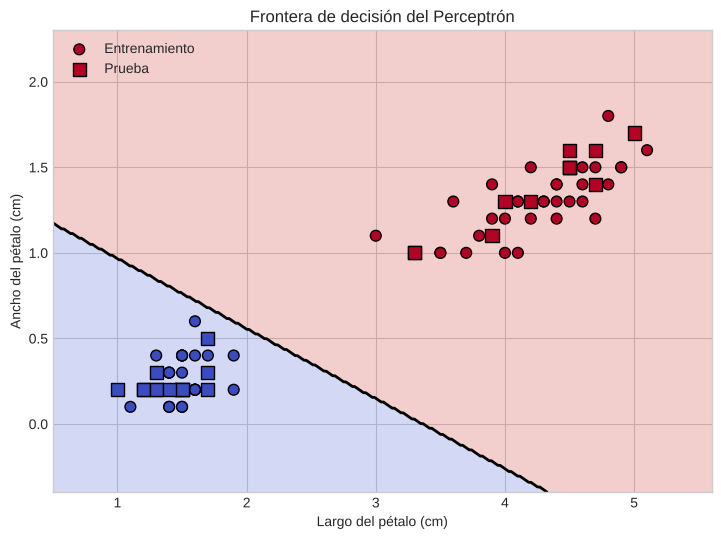

In [ ]:
# Definimos los límites del gráfico con un margen de 0.5 cm alrededor de los datos
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
# Límites del eje Y
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
# Creamos una malla de 300 x 300 puntos que cubre el plano
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
# Convertimos la malla en una lista de puntos (cada fila es un punto [largo, ancho])
grid = np.c_[xx.ravel(), yy.ravel()]
# Predecimos la clase de cada punto de la malla y devolvemos la forma 300 x 300
zz = model.predict(grid).reshape(xx.shape)

# Creamos la figura
plt.figure(figsize=(8.5, 6))
# Coloreamos las dos regiones de decisión (azul = clase 0, naranja = clase 1)
plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
# Dibujamos la frontera exacta: la curva de nivel 0.5 entre las dos clases
plt.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=2)
# Dibujamos los puntos de entrenamiento
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", edgecolor="k", s=60, label="Entrenamiento")
# Dibujamos los puntos de prueba con marcador de cuadrado
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", edgecolor="k", s=90, marker="s", label="Prueba")
# Etiqueta del eje X
plt.xlabel("Largo del pétalo (cm)")
# Etiqueta del eje Y
plt.ylabel("Ancho del pétalo (cm)")
# Título
plt.title("Frontera de decisión del Perceptrón")
# Leyenda
plt.legend(loc="upper left")
# Mostramos
plt.show()

La línea negra es la frontera: separa el plano en dos semiplanos, uno por clase. Todos los puntos quedan del lado correcto. Observa que **cualquier** recta que pase entre las dos nubes serviría; el Perceptrón se queda con la primera que encuentra (no busca la "mejor" ni la de mayor margen, a diferencia de una SVM).

**Interpretación.** Los errores por época llegan a **cero** en muy pocas épocas (aquí solo 2, porque las clases están muy separadas y los datos están estandarizados): en ese momento el algoritmo ha convergido, tal como lo garantiza el teorema de la sección 1.5. Con clases más cercanas entre sí harían falta más épocas. Los pesos de ambas implementaciones pueden diferir, porque para datos separables existen **infinitas rectas** que clasifican perfectamente; lo importante es que las dos separan bien las clases.